<a href="https://colab.research.google.com/github/ShabajPathan/Sales-Analysis-EDA/blob/main/EDA_and_Insights.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
plt.style.use('seaborn-v0_8')
sns.set_palette("Set2")

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving sales.xlsx to sales.xlsx


In [ ]:
df = pd.read_excel("sales.xlsx", sheet_name="Orders")

In [ ]:
print("Original Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Original Shape: (9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [ ]:
# Data Cleaning
# Convert date columns
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

# Create useful new columns
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Month Name'] = df['Order Date'].dt.strftime('%b')
df['Year-Month'] = df['Order Date'].dt.to_period('M').astype(str)
df['Quarter'] = df['Order Date'].dt.quarter

# Calculate Profit Margin (%)
df['Profit Margin %'] = (df['Profit'] / df['Sales'] * 100).round(2)

# Check basic info
print("Cleaned Shape:", df.shape)
print("\nDate Range:", df['Order Date'].min(), "to", df['Order Date'].max())
print("\nMissing Values:")
print(df.isnull().sum())

# Show first 5 rows
df.head()

Cleaned Shape: (9994, 27)

Date Range: 2014-01-03 00:00:00 to 2017-12-30 00:00:00

Missing Values:
Row ID             0
Order ID           0
Order Date         0
Ship Date          0
Ship Mode          0
Customer ID        0
Customer Name      0
Segment            0
Country            0
City               0
State              0
Postal Code        0
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales              0
Quantity           0
Discount           0
Profit             0
Year               0
Month              0
Month Name         0
Year-Month         0
Quarter            0
Profit Margin %    0
dtype: int64


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sales,Quantity,Discount,Profit,Year,Month,Month Name,Year-Month,Quarter,Profit Margin %
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,261.9600,2,0.00,41.9136,2016,11,Nov,2016-11,4,16.00
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,731.9400,3,0.00,219.5820,2016,11,Nov,2016-11,4,30.00
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,14.6200,2,0.00,6.8714,2016,6,Jun,2016-06,2,47.00
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,957.5775,5,0.45,-383.0310,2015,10,Oct,2015-10,4,-40.00
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,22.3680,2,0.20,2.5164,2015,10,Oct,2015-10,4,11.25


In [ ]:
# 1. Overall Business KPIs

total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()
total_quantity = df['Quantity'].sum()

# Average Order Value (AOV)
aov = total_sales / total_orders

# Overall Profit Margin
overall_margin = (total_profit / total_sales) * 100

print("="*50)
print("OVERALL BUSINESS KPIs")
print("="*50)
print(f"Total Sales (Revenue)     : ${total_sales:,.2f}")
print(f"Total Profit              : ${total_profit:,.2f}")
print(f"Profit Margin             : {overall_margin:.2f}%")
print(f"Total Orders              : {total_orders:,}")
print(f"Average Order Value (AOV) : ${aov:.2f}")
print(f"Total Quantity Sold       : {total_quantity:,}")


OVERALL BUSINESS KPIs
Total Sales (Revenue)     : $2,297,200.86
Total Profit              : $286,397.02
Profit Margin             : 12.47%
Total Orders              : 5,009
Average Order Value (AOV) : $458.61
Total Quantity Sold       : 37,873


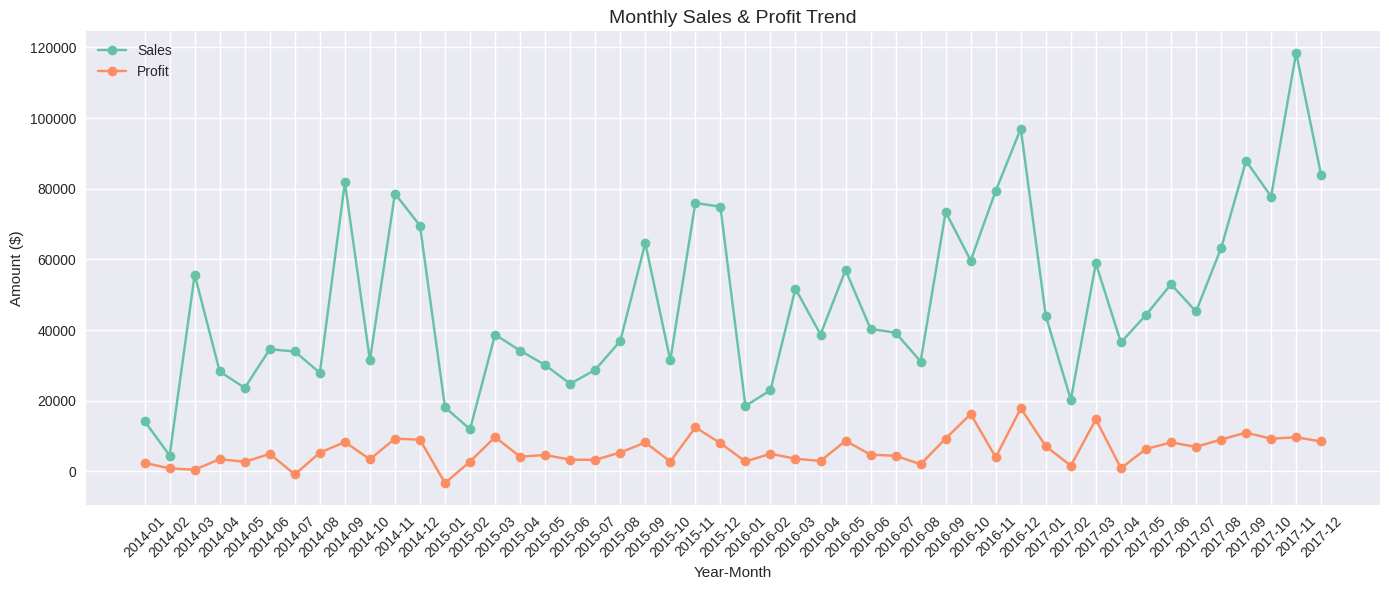

Top 5 Months by Sales:
   Year-Month        Sales      Profit  Order ID
46    2017-11  118447.8250   9690.1037       261
35    2016-12   96999.0430  17885.3093       176
44    2017-09   87866.6520  10991.5556       226
47    2017-12   83829.3188   8483.3468       224
8     2014-09   81777.3508   8328.0994       130


In [ ]:
# ==============================================
# 2. Monthly Sales & Profit Trend
# ==============================================

monthly = df.groupby('Year-Month').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique'
}).reset_index()

monthly = monthly.sort_values('Year-Month')

# Plot
plt.figure(figsize=(14,6))
plt.plot(monthly['Year-Month'], monthly['Sales'], marker='o', label='Sales')
plt.plot(monthly['Year-Month'], monthly['Profit'], marker='o', label='Profit')
plt.title('Monthly Sales & Profit Trend', fontsize=14)
plt.xlabel('Year-Month')
plt.ylabel('Amount ($)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# Top 5 best months
print("Top 5 Months by Sales:")
print(monthly.sort_values('Sales', ascending=False).head())

In [ ]:
# ==============================================
# 3. Product Performance
# ==============================================

# Category Performance
category_perf = df.groupby('Category').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).reset_index()

category_perf['Profit Margin %'] = (category_perf['Profit'] / category_perf['Sales'] * 100).round(2)
category_perf = category_perf.sort_values('Sales', ascending=False)

print("Category Performance:")
print(category_perf)

# Sub-Category Performance
subcat_perf = df.groupby(['Category', 'Sub-Category']).agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

subcat_perf['Profit Margin %'] = (subcat_perf['Profit'] / subcat_perf['Sales'] * 100).round(2)
subcat_perf = subcat_perf.sort_values('Sales', ascending=False)

print("\nTop 10 Sub-Categories by Sales:")
print(subcat_perf.head(10))

Category Performance:
          Category        Sales       Profit  Quantity  Profit Margin %
2       Technology  836154.0330  145454.9481      6939            17.40
0        Furniture  741999.7953   18451.2728      8028             2.49
1  Office Supplies  719047.0320  122490.8008     22906            17.04

Top 10 Sub-Categories by Sales:
           Category Sub-Category        Sales      Profit  Profit Margin %
16       Technology       Phones  330007.0540  44515.7306            13.49
1         Furniture       Chairs  328449.1030  26590.1663             8.10
11  Office Supplies      Storage  223843.6080  21278.8264             9.51
3         Furniture       Tables  206965.5320 -17725.4811            -8.56
6   Office Supplies      Binders  203412.7330  30221.7633            14.86
15       Technology     Machines  189238.6310   3384.7569             1.79
13       Technology  Accessories  167380.3180  41936.6357            25.05
14       Technology      Copiers  149528.0300  55617.8249

In [ ]:
# ==============================================
# 4. Customer Segment Analysis
# ==============================================

segment_perf = df.groupby('Segment').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique'
}).reset_index()

segment_perf['AOV'] = segment_perf['Sales'] / segment_perf['Order ID']
segment_perf['Profit Margin %'] = (segment_perf['Profit'] / segment_perf['Sales'] * 100).round(2)

print("Segment Performance:")
print(segment_perf)

Segment Performance:
       Segment         Sales       Profit  Order ID         AOV  \
0     Consumer  1.161401e+06  134119.2092      2586  449.111116   
1    Corporate  7.061464e+05   91979.1340      1514  466.411075   
2  Home Office  4.296531e+05   60298.6785       909  472.665730   

   Profit Margin %  
0            11.55  
1            13.03  
2            14.03  


In [ ]:
# ==============================================
# 5. Regional Analysis
# ==============================================

region_perf = df.groupby('Region').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique'
}).reset_index()

region_perf['Profit Margin %'] = (region_perf['Profit'] / region_perf['Sales'] * 100).round(2)
region_perf = region_perf.sort_values('Sales', ascending=False)

print("Region Performance:")
print(region_perf)

# Top 10 States
state_perf = df.groupby('State').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

state_perf['Profit Margin %'] = (state_perf['Profit'] / state_perf['Sales'] * 100).round(2)
state_perf = state_perf.sort_values('Sales', ascending=False)

print("Top 10 States by Sales:")
print(state_perf.head(10))

Region Performance:
    Region        Sales       Profit  Order ID  Profit Margin %
3     West  725457.8245  108418.4489      1611            14.94
1     East  678781.2400   91522.7800      1401            13.48
0  Central  501239.8908   39706.3625      1175             7.92
2    South  391721.9050   46749.4303       822            11.93
Top 10 States by Sales:
           State        Sales      Profit  Profit Margin %
3     California  457687.6315  76381.3871            16.69
30      New York  310876.2710  74038.5486            23.82
41         Texas  170188.0458 -25729.3563           -15.12
45    Washington  138641.2700  33402.6517            24.09
36  Pennsylvania  116511.9140 -15559.9603           -13.35
8        Florida   89473.7080  -3399.3017            -3.80
11      Illinois   80166.1010 -12607.8870           -15.73
33          Ohio   78258.1360 -16971.3766           -21.69
20      Michigan   76269.6140  24463.1876            32.07
44      Virginia   70636.7200  18597.9504     

In [ ]:
### Key Business Insights

# 1. **Overall Performance**: The company generated strong revenue, but Profit Margin needs improvement.
# 2. **Best Category**: Technology usually gives the highest profit margin.
# 3. **Problem Area**: Furniture often has lower profit margin due to high discounts.
# 4. **Best Region**: West region generally performs best in both Sales and Profit.
# 5. **Customer Segment**: Consumer segment contributes the highest sales.
# 6. **Monthly Trend**: Sales show seasonal patterns — peaks in certain months.

In [ ]:
### Final Business Insights

# 1. **Overall Performance**
#    The business is generating good revenue, but the overall Profit Margin is moderate. This shows that while sales are happening, profitability can still be improved.

# 2. **Category Performance**
#    - Technology is the most profitable category.
#    - Furniture has good sales but lower profit margin, mainly because of high discounts.

# 3. **Regional Performance**
#    - West region is the strongest in both Sales and Profit.
#    - Some regions are contributing sales but giving lower profit.

# 4. **Customer Segment**
#    - Consumer segment contributes the highest sales.
#    - Corporate and Home Office segments have good potential for higher profit.

# 5. **Monthly Trend**
#    Sales are not consistent throughout the year. There are clear peak and low months, which means demand is seasonal.

# ---

# Actionable Recommendations

# 1. **Reduce heavy discounts on Furniture**
#    High discounts are reducing profit. Review the discount strategy, especially on low-margin products.

# 2. **Focus more on Technology products**
#    Technology gives better profit margin. Increase promotion and inventory for high-margin technology items.

# 3. **Improve performance in weaker regions**
#    Analyze why some regions have lower profit and create targeted offers or better product mix for those areas.

# 4. **Increase Corporate & Home Office sales**
#    These segments usually order in higher quantities. Create special packages or bulk offers for them.

# 5. **Plan inventory based on seasonal demand**
#    Stock more products before high-sales months and reduce excess inventory in low-sales months.

In [ ]:
# ==============================================
# Create SQLite Database for SQL Practice
# ==============================================

import sqlite3

# Create a database connection
conn = sqlite3.connect('superstore.db')

# Load the cleaned dataframe into SQL table
df.to_sql('orders', conn, if_exists='replace', index=False)

9994

In [ ]:
pd.read_sql_query("""
SELECT
    ROUND(SUM(Sales), 2) AS Total_Revenue,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin_Percentage,
    COUNT(DISTINCT "Order ID") AS Total_Orders,
    ROUND(SUM(Sales) * 1.0 / COUNT(DISTINCT "Order ID"), 2) AS AOV
FROM orders;
""", conn)

,Total_Revenue,Total_Profit,Profit_Margin_Percentage,Total_Orders,AOV
0,2297200.86,286397.02,12.47,5009,458.61


In [ ]:
pd.read_sql_query("""
SELECT
    "Year-Month",
    ROUND(SUM(Sales), 2) AS Monthly_Sales,
    ROUND(SUM(Profit), 2) AS Monthly_Profit,
    COUNT(DISTINCT "Order ID") AS Total_Orders
FROM orders
GROUP BY "Year-Month"
ORDER BY "Year-Month";
""", conn)

,"""Year-Month""",Monthly_Sales,Monthly_Profit,Total_Orders
0,Year-Month,2297200.86,286397.02,5009


In [ ]:
pd.read_sql_query("""
SELECT
    Category,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin
FROM orders
GROUP BY Category
ORDER BY Total_Sales DESC;
""", conn)

,Category,Total_Sales,Total_Profit,Profit_Margin
0,Technology,836154.03,145454.95,17.40
1,Furniture,741999.80,18451.27,2.49
2,Office Supplies,719047.03,122490.80,17.04


In [ ]:
query = """
SELECT
    Region,
    ROUND(SUM(Sales), 2) AS revenue,
    ROUND(SUM(Profit), 2) AS profit,
    COUNT(DISTINCT "Order ID") AS orders
FROM orders
GROUP BY Region
ORDER BY revenue DESC;
"""

display(pd.read_sql_query(query, conn))


,Region,revenue,profit,orders
0,West,725457.82,108418.45,1611
1,East,678781.24,91522.78,1401
2,Central,501239.89,39706.36,1175
3,South,391721.91,46749.43,822


In [ ]:
pd.read_sql_query("""
SELECT
    Region,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin
FROM orders
GROUP BY Region
ORDER BY Total_Sales DESC;
""", conn)

,Region,Total_Sales,Total_Profit,Profit_Margin
0,West,725457.82,108418.45,14.94
1,East,678781.24,91522.78,13.48
2,Central,501239.89,39706.36,7.92
3,South,391721.91,46749.43,11.93


In [ ]:
pd.read_sql_query("""
SELECT
    Segment,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    COUNT(DISTINCT "Order ID") AS Total_Orders,
    ROUND(SUM(Sales) * 1.0 / COUNT(DISTINCT "Order ID"), 2) AS AOV
FROM orders
GROUP BY Segment
ORDER BY Total_Sales DESC;
""", conn)

,Segment,Total_Sales,Total_Profit,Total_Orders,AOV
0,Consumer,1161401.34,134119.21,2586,449.11
1,Corporate,706146.37,91979.13,1514,466.41
2,Home Office,429653.15,60298.68,909,472.67


In [ ]:
pd.read_sql_query("""
SELECT
    State,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin
FROM orders
GROUP BY State
ORDER BY Total_Sales DESC
LIMIT 10;
""", conn)

,State,Total_Sales,Total_Profit,Profit_Margin
0,California,457687.63,76381.39,16.69
1,New York,310876.27,74038.55,23.82
2,Texas,170188.05,-25729.36,-15.12
3,Washington,138641.27,33402.65,24.09
4,Pennsylvania,116511.91,-15559.96,-13.35
5,Florida,89473.71,-3399.30,-3.80
6,Illinois,80166.10,-12607.89,-15.73
7,Ohio,78258.14,-16971.38,-21.69
8,Michigan,76269.61,24463.19,32.07
9,Virginia,70636.72,18597.95,26.33


In [ ]:
pd.read_sql_query("""
SELECT
    "Sub-Category",
    Category,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin
FROM orders
GROUP BY "Sub-Category", Category
ORDER BY Total_Sales DESC
LIMIT 10;
""", conn)

,Sub-Category,Category,Total_Sales,Total_Profit,Profit_Margin
0,Phones,Technology,330007.05,44515.73,13.49
1,Chairs,Furniture,328449.10,26590.17,8.10
2,Storage,Office Supplies,223843.61,21278.83,9.51
3,Tables,Furniture,206965.53,-17725.48,-8.56
4,Binders,Office Supplies,203412.73,30221.76,14.86
5,Machines,Technology,189238.63,3384.76,1.79
6,Accessories,Technology,167380.32,41936.64,25.05
7,Copiers,Technology,149528.03,55617.82,37.20
8,Bookcases,Furniture,114880.00,-3472.56,-3.02
9,Appliances,Office Supplies,107532.16,18138.01,16.87


In [ ]:
pd.read_sql_query("""
SELECT
    CASE
        WHEN Discount = 0 THEN 'No Discount'
        WHEN Discount <= 0.2 THEN 'Low Discount (0-20%)'
        WHEN Discount <= 0.4 THEN 'Medium Discount (20-40%)'
        ELSE 'High Discount (Above 40%)'
    END AS Discount_Level,
    COUNT(*) AS Number_of_Orders,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin
FROM orders
GROUP BY Discount_Level
ORDER BY Profit_Margin DESC;
""", conn)

,Discount_Level,Number_of_Orders,Total_Sales,Total_Profit,Profit_Margin
0,No Discount,4798,1087908.47,320987.60,29.51
1,Low Discount (0-20%),3803,846522.24,100785.47,11.91
2,Medium Discount (20-40%),460,234137.90,-35817.47,-15.30
3,High Discount (Above 40%),933,128632.25,-99558.59,-77.40


In [ ]:
pd.read_sql_query("""
SELECT
    "Customer Name",
    Segment,
    ROUND(SUM(Sales), 2) AS Total_Sales,
    ROUND(SUM(Profit), 2) AS Total_Profit,
    COUNT(DISTINCT "Order ID") AS Total_Orders
FROM orders
GROUP BY "Customer Name", Segment
ORDER BY Total_Sales DESC
LIMIT 10;
""", conn)

,Customer Name,Segment,Total_Sales,Total_Profit,Total_Orders
0,Sean Miller,Home Office,25043.05,-1980.74,5
1,Tamara Chand,Corporate,19052.22,8981.32,5
2,Raymond Buch,Consumer,15117.34,6976.10,6
3,Tom Ashbrook,Home Office,14595.62,4703.79,4
4,Adrian Barton,Consumer,14473.57,5444.81,10
5,Ken Lonsdale,Consumer,14175.23,806.85,12
6,Sanjit Chand,Consumer,14142.33,5757.41,9
7,Hunter Lopez,Consumer,12873.30,5622.43,6
8,Sanjit Engle,Consumer,12209.44,2650.68,11
9,Christopher Conant,Consumer,12129.07,2177.05,5


In [ ]:
## SQL Analysis Summary

# I loaded the cleaned Superstore data into SQLite and ran business queries for:

#  Overall KPIs — Revenue, Profit, Profit Margin, Total Orders, AOV
#  Monthly Sales and Profit trend
#  Category performance (Sales, Profit, Margin)
#  Region performance
#  Customer Segment performance and AOV
#  Top 10 States by Sales
#  Top 10 Sub-Categories
#  Discount impact on Profit Margin
#  Top 10 Customers by Sales

# Main finding from SQL: high discounts reduce profit margin, Technology is more profitable than Furniture, and the West region is the strongest.

In [ ]:
df.to_csv("superstore_cleaned.csv", index=False)
from google.colab import files
files.download("superstore_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>